## 03 · Model

This notebook tests whether supply chain pressure (GSCPI) helps forecast the future change in the metals index beyond demand, oil, the US dollar and momentum.

**Input:** `data/processed/analysis_dataset.csv` from notebook `02_prepare_data`.

**Output:** result tables in `results/` and figures in `figures/`.

**Steps:**

1. **Momentum test:** does the past price change help forecast the future change?
2. **In-sample regressions:** Model A (without GSCPI), Model B (with GSCPI) and Model C (with a high-pressure interaction), with Newey-West standard errors and diagnostics.
3. **Out-of-sample forecasts:** expanding window from 2011 and a train/test split at 2015, compared with simple benchmarks.
4. **Gaussian process:** a nonlinear model with the same predictors.
5. **Individual metals** and **robustness checks**.

*Code written with help of Claude (Anthropic), asked to guide on how to produce clean code that estimates the forecasting models, evaluates them in and out of sample, and runs the robustness checks.*

In [42]:
### Load packages 

from pathlib import Path
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan, acorr_ljungbox
from statsmodels.stats.stattools import jarque_bera
from statsmodels.graphics.tsaplots import plot_acf
from scipy import stats
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, RBF, WhiteKernel
from sklearn.preprocessing import StandardScaler
from sklearn.exceptions import ConvergenceWarning

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import warnings
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=ConvergenceWarning)

PROCESSED = Path("../data/processed")
FIGURES = Path("../figures")
RESULTS = Path("../results")
RESULTS.mkdir(exist_ok=True)

In [2]:
### Loading the necessary data 

analysis = pd.read_csv(PROCESSED / "analysis_dataset.csv", index_col="date", parse_dates=True)

print(f"{analysis.index.min():%Y-%m} to {analysis.index.max():%Y-%m}: "
      f"{len(analysis)} months, {analysis.shape[1]} columns")

2001-02 to 2026-05: 304 months, 30 columns


In [ ]:
### Global model settings

TARGET = "index_worldbank_next_3m"
MOMENTUM = "index_worldbank_past_3m"
GSCPI = "gscpi_lag"
CONTROLS = ["demand_world_12m_lag", "oil_3m_lag", "usd_3m_lag"]

MODEL_A = [MOMENTUM] + CONTROLS   # without supply chain pressure
MODEL_B = MODEL_A + [GSCPI]       # with supply chain pressure

NW_LAGS = 3             # Newey-West lags (overlapping 3-month targets)
OOS_START = "2011-01"   # first out-of-sample forecast
SPLIT_DATE = "2015-01"  # start of the test period
HIGH_PRESSURE = 1       # GSCPI threshold for high pressure
HORIZON = 3             # forecast horizon in months

EPISODES = {
    "Financial\ncrisis": ("2007-12", "2009-06"),
    "Oil\ncrash": ("2014-07", "2016-01"),
    "COVID and\nsupply chain crisis": ("2020-02", "2023-01"),
}

In [ ]:
### Helper functions
### Reusable functions for estimation and evaluation. Out-of-sample forecasts use an expanding window: each forecast is based only on targets that were already known at the time of the forecast.

def fit_regression(data, predictors, target=TARGET):
    """In-sample OLS regression with Newey-West standard errors."""
    predictors_with_constant = sm.add_constant(data[predictors])
    return sm.OLS(data[target], predictors_with_constant).fit(
        cov_type="HAC", cov_kwds={"maxlags": NW_LAGS}
    )


def forecast_out_of_sample(data, predictors, target=TARGET, start=OOS_START, window_years=None):
    """
    One forecast per month from `start` on.
    Training data ends HORIZON months earlier, when the latest target becomes known.
    window_years=None: expanding window (all past data); a number: rolling window of that length.
    Without predictors, the forecast is the historical mean of the target.
    """
    forecasts = {}
    for forecast_month in data.loc[start:].index:
        training_end = forecast_month - pd.DateOffset(months=HORIZON) # last known month for the target
        training_start = None if window_years is None else training_end - pd.DateOffset(years=window_years) # first month of the training window
        training_data = data.loc[training_start:training_end] # subset of data used for the training

        if not predictors: # if no predictors are provided (empty list), use the historical mean benchmark
            forecasts[forecast_month] = training_data[target].mean()
            continue

        fitted_model = sm.OLS(training_data[target], sm.add_constant(training_data[predictors])).fit() # fit the model on the training data
        forecast_row = sm.add_constant(data.loc[[forecast_month], predictors], has_constant="add") # prepare the row for forecasting 
        forecasts[forecast_month] = fitted_model.predict(forecast_row).iloc[0] # store the forecast for the current month 

    return pd.Series(forecasts, name="forecast")


def forecast_mse(actual, forecast):
    """Mean squared forecast error."""
    return ((actual - forecast) ** 2).mean()


def out_of_sample_r2(actual, forecast, benchmark):
    """Share of the benchmark's squared forecast error removed by the forecast."""
    return 1 - ((actual - forecast) ** 2).sum() / ((actual - benchmark) ** 2).sum()

In [7]:
### Momentum test
### Does the past three-month change in the metals index help forecast the future change? In sample, the future change is regressed on momentum (Newey-West standard errors). Out of sample, a momentum-only forecast is compared with the historical mean.

momentum_regression = fit_regression(analysis, [MOMENTUM])

print("in sample (Newey-West standard errors)")
print(f"  coefficient: {momentum_regression.params[MOMENTUM]:.2f}")
print(f"  p-value:     {momentum_regression.pvalues[MOMENTUM]:.3f}")
print(f"  R²:          {momentum_regression.rsquared:.3f}")

actual = analysis.loc[OOS_START:, TARGET]
historical_mean_forecast = forecast_out_of_sample(analysis, [])
momentum_forecast = forecast_out_of_sample(analysis, [MOMENTUM])

print(f"\nout of sample ({OOS_START} onward, {len(actual)} forecasts)")
print(f"  MSE historical mean: {forecast_mse(actual, historical_mean_forecast):.5f}")
print(f"  MSE momentum:        {forecast_mse(actual, momentum_forecast):.5f}")
print(f"  R²_OOS:              {100 * out_of_sample_r2(actual, momentum_forecast, historical_mean_forecast):.1f}%")

in sample (Newey-West standard errors)
  coefficient: 0.22
  p-value:     0.037
  R²:          0.048

out of sample (2011-01 onward, 185 forecasts)
  MSE historical mean: 0.00773
  MSE momentum:        0.00784
  R²_OOS:              -1.4%


In [10]:
def without_episodes(*episodes):
    """The sample without the months of the given episodes."""
    in_episode = np.zeros(len(analysis), dtype=bool)
    for episode in episodes:
        start, end = EPISODES[episode]
        in_episode |= (analysis.index >= start) & (analysis.index <= end)
    return analysis[~in_episode]


subsamples = {"full sample": analysis}
for episode in EPISODES:
    subsamples[f"without {episode}"] = without_episodes(episode)
subsamples["without all three"] = without_episodes(*EPISODES)

rows = []
for name, sample in subsamples.items():
    regression = fit_regression(sample, [MOMENTUM])
    rows.append({
        "sample": name,
        "months": len(sample),
        "coefficient": regression.params[MOMENTUM],
        "p-value": regression.pvalues[MOMENTUM],
        "R²": regression.rsquared,
    })

pd.DataFrame(rows).set_index("sample").round(3)

,months,coefficient,p-value,R²
sample,,,,
full sample,304,0.218,0.037,0.048
without financial crisis,285,0.147,0.068,0.023
without oil crash,285,0.211,0.057,0.045
without supply chain crisis,268,0.245,0.037,0.059
without all three,230,0.151,0.110,0.024


**Interpretation.** Momentum has a positive and statistically significant relationship with the future change in the metals index in the full sample ($\beta = 0.218$, $p = 0.037$), although its explanatory power is modest ($R^2 = 0.048$). Excluding the 2008–09 financial crisis reduces the coefficient to 0.147 ($p = 0.068$). Excluding the oil crash leaves the coefficient largely unchanged (0.211); its p-value rises to 0.057, mainly because of the smaller sample. Conversely, excluding the 2020–23 supply chain crisis increases the coefficient to 0.245 ($p = 0.037$). Without all three episodes, momentum is not statistically significant ($p = 0.110$). Out of sample, momentum does not outperform the historical mean ($R^2_{OOS} = -1.4$%).

Momentum is nevertheless retained as a control for return persistence, consistent with the commodity momentum literature (Moskowitz et al., 2012). It was specified from the outset and enters Models A and B alike, so it does not affect their comparison. Its correlation with the GSCPI is weak (0.14). Specifications without momentum are reported as a robustness check.

In [13]:
### In-sample regressions: 
### Model A uses momentum, demand, oil and the US dollar. 
### Model B adds the GSCPI. 
### Model C additionally allows the GSCPI effect to differ in high-pressure months (GSCPI > 1), through a high-pressure dummy and its interaction with the GSCPI. Coefficients are shown with Newey-West p-values in brackets.
### The last rows report Wald tests of whether the GSCPI terms are jointly zero.

# Model C: high-pressure dummy and the GSCPI effect in high-pressure months
HIGH_PRESSURE_DUMMY = "high_pressure"
GSCPI_IN_HIGH = "gscpi_in_high_pressure"

analysis[HIGH_PRESSURE_DUMMY] = (analysis[GSCPI] > HIGH_PRESSURE).astype(int)
analysis[GSCPI_IN_HIGH] = analysis[GSCPI] * analysis[HIGH_PRESSURE_DUMMY]
MODEL_C = MODEL_B + [HIGH_PRESSURE_DUMMY, GSCPI_IN_HIGH]

# fit the three models (Newey-West standard errors)
model_predictors = {"Model A": MODEL_A, "Model B": MODEL_B, "Model C": MODEL_C}
fitted_models = {name: fit_regression(analysis, predictors)
                 for name, predictors in model_predictors.items()}


def joint_test_p_value(fitted_model, variables):
    """p-value of a Wald test that the given coefficients are jointly zero (only those in the model)."""
    included = [variable for variable in variables if variable in fitted_model.params]
    if not included:
        return ""
    hypothesis = ", ".join(f"{variable} = 0" for variable in included)
    return f"{fitted_model.wald_test(hypothesis, scalar=True).pvalue:.3f}"


def summarise_model(fitted_model):
    """One column of the comparison table: coefficients with p-values, fit and joint tests."""
    column = {}
    for variable in ["const"] + MODEL_C:
        if variable in fitted_model.params:
            column[variable] = f"{fitted_model.params[variable]:.3f} ({fitted_model.pvalues[variable]:.3f})"
        else:
            column[variable] = ""
    column["R²"] = f"{fitted_model.rsquared:.3f}"
    column["adjusted R²"] = f"{fitted_model.rsquared_adj:.3f}"
    column["all GSCPI terms = 0 (p)"] = joint_test_p_value(fitted_model, [GSCPI, HIGH_PRESSURE_DUMMY, GSCPI_IN_HIGH])
    column["high-pressure terms = 0 (p)"] = joint_test_p_value(fitted_model, [HIGH_PRESSURE_DUMMY, GSCPI_IN_HIGH])
    column["months"] = int(fitted_model.nobs)
    return column


# comparison table: one column per model
model_comparison = pd.DataFrame({name: summarise_model(fitted_model)
                                 for name, fitted_model in fitted_models.items()})
model_comparison

,Model A,Model B,Model C
const,0.019 (0.128),0.019 (0.129),0.018 (0.238)
index_worldbank_past_3m,0.289 (0.026),0.285 (0.033),0.281 (0.032)
demand_world_12m_lag,-0.311 (0.230),-0.315 (0.224),-0.327 (0.221)
oil_3m_lag,-0.144 (0.007),-0.146 (0.004),-0.144 (0.004)
usd_3m_lag,-0.464 (0.159),-0.481 (0.149),-0.550 (0.082)
gscpi_lag,,0.003 (0.767),-0.004 (0.844)
high_pressure,,,-0.074 (0.365)
gscpi_in_high_pressure,,,0.035 (0.391)
R²,0.114,0.114,0.122
adjusted R²,0.102,0.099,0.101


In [15]:
def r2_contributions(data, predictors, target=TARGET):
    """Unique contribution of each predictor: how much R² falls when it is dropped from the model."""
    full_r2 = fit_regression(data, predictors, target).rsquared
    rows = []
    for dropped_predictor in predictors:
        remaining_predictors = [p for p in predictors if p != dropped_predictor]
        r2_without = fit_regression(data, remaining_predictors, target).rsquared
        rows.append({
            "predictor": dropped_predictor,
            "R² without it": r2_without,
            "R² lost": full_r2 - r2_without,
            "share of full R² (%)": 100 * (full_r2 - r2_without) / full_r2,
        })
    return pd.DataFrame(rows).set_index("predictor").sort_values("R² lost", ascending=False)


print(f"R² of Model A: {fitted_models['Model A'].rsquared:.3f}")
r2_contributions(analysis, MODEL_A).round(3)

R² of Model A: 0.114


,R² without it,R² lost,share of full R² (%)
predictor,,,
index_worldbank_past_3m,0.058,0.056,48.837
oil_3m_lag,0.072,0.041,36.310
demand_world_12m_lag,0.103,0.011,9.568
usd_3m_lag,0.106,0.008,7.110


**Interpretation.** The controls explain about 11% of the variation in the future change of the metals index ($R^2 = 0.114$), mainly through momentum (about half of the $R^2$) and oil (about a third), meanwhile demand and the US dollar contribute little. Adding the GSCPI variable leaves the $R^2$ and the other coefficients unchanged and diminishes the adjusted $R^2$. Its coefficient is close to zero ($p = 0.767$), and allowing a separate effect under high pressure does not help either (high-pressure terms jointly $p = 0.653$, all GSCPI terms jointly $p = 0.768$). In sample, supply chain pressure therefore adds no explanatory power beyond the controls, neither on average nor in high-pressure months.

In [ ]:
# Model B (main model)
main_model = fitted_models["Model B"]
residuals = main_model.resid                       
X = sm.add_constant(analysis[MODEL_B])             

# 1. multicollinearity: VIF for each predictor (constant skipped)
vif_rows = []
for position, predictor in enumerate(X.columns):
    if predictor == "const":
        continue
    vif = variance_inflation_factor(X.values, position)
    vif_rows.append({
        "predictor": predictor,
        "VIF": round(vif, 2),
        "explained by other predictors (%)": round(100 * (1 - 1 / vif)),
        "multicollinearity": "problem" if vif > 5 else "no",
    })
vif_table = pd.DataFrame(vif_rows).set_index("predictor")

# 2. residual tests: p < 0.05 = the assumption is violated
test_rows = [
    ("Breusch-Pagan", "constant error variance", het_breuschpagan(residuals, X)[1]),
    ("Jarque-Bera", "normally distributed errors", jarque_bera(residuals)[1]),
    ("Ljung-Box, 3 lags", "no autocorrelation", acorr_ljungbox(residuals, lags=[3])["lb_pvalue"].iloc[0]),
    ("Ljung-Box, 12 lags", "no autocorrelation", acorr_ljungbox(residuals, lags=[12])["lb_pvalue"].iloc[0]),
]
test_table = pd.DataFrame(test_rows, columns=["test", "assumption", "p-value"]).set_index("test")
test_table["assumption holds"] = test_table["p-value"].map(lambda p: "no" if p < 0.05 else "yes")
test_table["p-value"] = test_table["p-value"].map(lambda p: "< 0.001" if p < 0.001 else f"{p:.3f}")

print("Multicollinearity (VIF above 5 is a concern)")
display(vif_table)
print("\nResidual tests (p < 0.05: assumption violated)")
display(test_table)

Multicollinearity (VIF above 5 is a concern)


,VIF,explained by other predictors (%),multicollinearity
predictor,,,
index_worldbank_past_3m,1.53,35,no
demand_world_12m_lag,1.09,8,no
oil_3m_lag,1.53,35,no
usd_3m_lag,1.57,36,no
gscpi_lag,1.06,6,no



Residual tests (p < 0.05: assumption violated)


,assumption,p-value,assumption holds
test,,,
Breusch-Pagan,constant error variance,0.027,no
Jarque-Bera,normally distributed errors,< 0.001,no
"Ljung-Box, 3 lags",no autocorrelation,< 0.001,no
"Ljung-Box, 12 lags",no autocorrelation,< 0.001,no


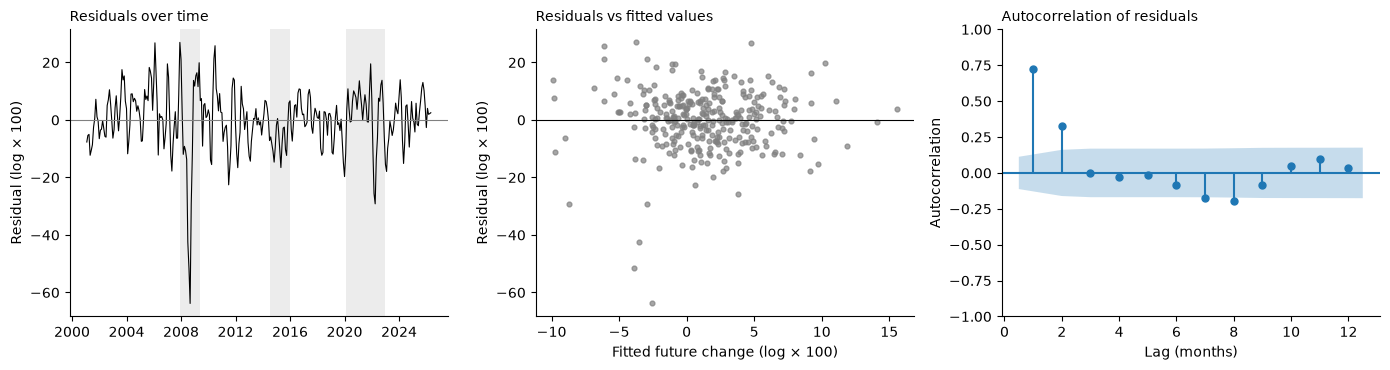

In [ ]:
### Residual plots
### Residuals of Model B over time, against fitted values, and their autocorrelation.

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))

# 1. residuals over time, with crisis episodes shaded
for start, end in EPISODES.values():
    axes[0].axvspan(pd.Timestamp(start), pd.Timestamp(end), color="grey", alpha=0.15, linewidth=0)
axes[0].plot(residuals.index, 100 * residuals, color="black", linewidth=0.8)
axes[0].axhline(0, color="grey", linewidth=0.8)
axes[0].set_ylabel("Residual (log × 100)")
axes[0].set_title("Residuals over time", loc="left", fontsize=10)

# 2. residuals against fitted values
axes[1].scatter(100 * main_model.fittedvalues, 100 * residuals, s=12, color="grey", alpha=0.7)
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_xlabel("Fitted future change (log × 100)")
axes[1].set_ylabel("Residual (log × 100)")
axes[1].set_title("Residuals vs fitted values", loc="left", fontsize=10)

# 3. autocorrelation of the residuals
plot_acf(residuals, lags=12, zero=False, ax=axes[2], title="")
axes[2].set_xlabel("Lag (months)")
axes[2].set_ylabel("Autocorrelation")
axes[2].set_title("Autocorrelation of residuals", loc="left", fontsize=10)

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()
fig.savefig(FIGURES / "residual_diagnostics.png", dpi=150)
plt.show()

In [23]:
print((100 * residuals).nsmallest(5).round(1))
print((100 * residuals).nlargest(5).round(1))

date
2008-09-01   -63.8
2008-08-01   -51.6
2008-07-01   -42.5
2008-10-01   -29.2
2022-04-01   -29.2
dtype: float64
date
2007-12-01    27.0
2006-02-01    26.8
2010-07-01    25.8
2010-06-01    21.3
2008-01-01    21.1
dtype: float64


**Interpretation.** The largest negative residuals occur in July–October 2008 and April 2022, when prices fell more than predicted; the largest positive residuals occur in 2006–08 and mid-2010. Negative errors are larger than positive ones (−64 vs +27 log points). Residuals show no clear pattern against fitted values. Residual autocorrelation is significant at lags 1 and 2, consistent with the overlapping targets.

In [ ]:
### High-pressure months available for training
### Model C needs high-pressure months in its training data. Before 2020, the GSCPI exceeded the threshold only rarely.

high_pressure_months = analysis.index[analysis[GSCPI] > HIGH_PRESSURE]
before_2020 = high_pressure_months[high_pressure_months < "2020-01"]

print(f"high-pressure months before 2020: {len(before_2020)} ({', '.join(before_2020.strftime('%Y-%m'))})")
print(f"high-pressure months in total:    {len(high_pressure_months)}")

high-pressure months before 2020: 2 (2008-08, 2011-05)
high-pressure months in total:    35


**Interpretation.** Of the 35 high-pressure months, only two (August 2008 and May 2011) occur before 2020. Until the supply chain crisis, any model is therefore trained on almost no high-pressure observations, which is why Model C cannot be evaluated out of sample.

## Out-of-sample forecasts

**Design.** Each month from January 2011 to May 2026, every model produces a point forecast of the future change, using only data known at that time (expanding window, training data ending three months before the forecast date). This simulates real-time forecasting over 185 months.

**Models.**
- *No change:* forecasts zero.
- *Historical mean:* forecasts the average of past targets.
- *Model A:* momentum, demand, oil and the US dollar.
- *Model B:* Model A plus the GSCPI.

Model C is not evaluated out of sample, as the training data contain only two high-pressure months before 2020, too few to estimate the high-pressure terms.

**Evaluation.**
- *MSFE:* mean squared forecast error; lower is better.
- *$R^2_{OOS}$:* reduction in squared forecast error relative to a benchmark (historical mean or Model A), where positive values indicate  that the model forecasts better than the benchmark.
- *Subsamples:* the comparison with Model A is repeated for the supply chain crisis (February 2020 to January 2023) and for the remaining months, to show where gains or losses arise.
- *Clark-West test:* since Model B nests Model A, a plain comparison of MSFEs would be biased against the larger model, therefore, the Clark-West (2007) test corrects specifically this issue. The one-sided p-value tests whether Model B forecasts better than Model A.

In [30]:
def clark_west_p_value(y_true, y_hat_restricted, y_hat_unrestricted):
    """
    Clark-West (2007) test of equal predictive accuracy for nested models.
    H0: the unrestricted model does not forecast better than the restricted one.
    Returns a one-sided p-value (Newey-West standard errors, as forecast errors overlap).
    """
    e_restricted = y_true - y_hat_restricted            # forecast errors, restricted model (A)
    e_unrestricted = y_true - y_hat_unrestricted        # forecast errors, unrestricted model (B)
    adjustment = (y_hat_restricted - y_hat_unrestricted) ** 2

    f_t = e_restricted**2 - (e_unrestricted**2 - adjustment)   # adjusted loss differential

    mean_regression = sm.OLS(f_t, np.ones(len(f_t))).fit(cov_type="HAC", cov_kwds={"maxlags": NW_LAGS})
    t_stat = mean_regression.tvalues.iloc[0]
    return 1 - stats.norm.cdf(t_stat)


def r2_oos_percent(y_hat, y_hat_benchmark, sample):
    """Out-of-sample R² (%) of y_hat relative to a benchmark forecast, over the selected months."""
    return 100 * out_of_sample_r2(y_true[sample], y_hat[sample], y_hat_benchmark[sample])


# --- 1. realised values of the target over the evaluation period
y_true = analysis.loc[OOS_START:, TARGET]

# --- 2. point forecasts (expanding window, data known at each forecast date)
y_hat = {
    "no change": pd.Series(0.0, index=y_true.index),
    "historical mean": forecast_out_of_sample(analysis, []),
    "Model A": forecast_out_of_sample(analysis, MODEL_A),
    "Model B": forecast_out_of_sample(analysis, MODEL_B),
}

# --- 3. evaluation subsamples
crisis_start, crisis_end = EPISODES["supply chain crisis"]
crisis = (y_true.index >= crisis_start) & (y_true.index <= crisis_end)
full = np.ones(len(y_true), dtype=bool)

# --- 4. forecast evaluation: MSFE, out-of-sample R², Clark-West
rows = []
for model, y_hat_model in y_hat.items():
    rows.append({
        "model": model,
        "MSFE": forecast_mse(y_true, y_hat_model),
        "R²_OOS vs historical mean (%)": r2_oos_percent(y_hat_model, y_hat["historical mean"], full),
        "R²_OOS vs Model A (%)": r2_oos_percent(y_hat_model, y_hat["Model A"], full),
        "vs Model A, supply chain crisis (%)": r2_oos_percent(y_hat_model, y_hat["Model A"], crisis),
        "vs Model A, other months (%)": r2_oos_percent(y_hat_model, y_hat["Model A"], ~crisis),
        "Clark-West p vs Model A": (clark_west_p_value(y_true, y_hat["Model A"], y_hat_model)
                                    if model == "Model B" else np.nan),
    })

oos_evaluation = pd.DataFrame(rows).set_index("model")
decimals = {column: 1 for column in oos_evaluation.columns} | {"MSFE": 5, "Clark-West p vs Model A": 3}
oos_evaluation = oos_evaluation.round(decimals)

print(f"evaluation period: {y_true.index.min():%Y-%m} to {y_true.index.max():%Y-%m} "
      f"({len(y_true)} forecasts, {crisis.sum()} in the supply chain crisis)")
oos_evaluation

evaluation period: 2011-01 to 2026-05 (185 forecasts, 36 in the supply chain crisis)


,MSFE,R²_OOS vs historical mean (%),R²_OOS vs Model A (%),"vs Model A, supply chain crisis (%)","vs Model A, other months (%)",Clark-West p vs Model A
model,,,,,,
no change,0.00741,4.2,0.8,-20.7,11.8,NaN
historical mean,0.00773,0.0,-3.6,-17.0,3.3,NaN
Model A,0.00746,3.5,0.0,0.0,0.0,NaN
Model B,0.00825,-6.7,-10.6,-34.6,1.7,0.75


**Interpretation.** All models have forecast errors of roughly 9 log points. Model A and the no-change forecast slightly outperform the historical mean ($R^2_{OOS}$ of 3.5% and 4.2%) and perform similarly overall. Adding the GSCPI worsens the forecasts. Model B underperforms the historical mean ($R^2_{OOS} = -6.7$%) and Model A ($-10.6$%), and the Clark-West test shows no improvement ($p = 0.75$). The losses are concentrated in the supply chain crisis ($-34.6$% relative to Model A), when the GSCPI attained values far above those in the training data. In the remaining months, Models A and B perform similarly (+1.7%). During the crisis, Model A clearly outperforms the no-change forecast, whereas the reverse holds in the remaining months.

In [ ]:
### For each predictor, compare two forecasting models that differ only in that predictor:
# full model:    all predictors
# reduced model: all predictors except this one
# A positive gain means the predictor improves the out-of-sample forecasts.

rows = []

# controls: full Model A vs Model A without the predictor
for predictor in MODEL_A:
    reduced_predictors = [p for p in MODEL_A if p != predictor]
    y_hat_reduced = forecast_out_of_sample(analysis, reduced_predictors)
    y_hat_full = y_hat["Model A"]
    rows.append({
        "predictor": predictor,
        "gain from adding it (%)": 100 * out_of_sample_r2(y_true, y_hat_full, y_hat_reduced),
        "Clark-West p": clark_west_p_value(y_true, y_hat_reduced, y_hat_full),
    })

# GSCPI: Model B (Model A plus the GSCPI) vs Model A
rows.append({
    "predictor": GSCPI,
    "gain from adding it (%)": 100 * out_of_sample_r2(y_true, y_hat["Model B"], y_hat["Model A"]),
    "Clark-West p": clark_west_p_value(y_true, y_hat["Model A"], y_hat["Model B"]),
})

predictor_contributions = pd.DataFrame(rows).set_index("predictor")
predictor_contributions.round({"gain from adding it (%)": 1, "Clark-West p": 3})

,gain from adding it (%),Clark-West p
predictor,,
index_worldbank_past_3m,0.7,0.025
demand_world_12m_lag,0.5,0.187
oil_3m_lag,4.0,0.033
usd_3m_lag,0.2,0.257
gscpi_lag,-10.6,0.750


In [ ]:
def forecast_train_test(data, predictors, target=TARGET, split_date=SPLIT_DATE):
    """
    Fit the model once on the training period, then forecast every month of the test period.
    Training ends HORIZON months before the split, so no training target overlaps the test period.
    """
    last_training_month = pd.Timestamp(split_date) - pd.DateOffset(months=HORIZON)
    training_data = data.loc[:last_training_month]
    test_data = data.loc[split_date:]

    model = sm.OLS(training_data[target], sm.add_constant(training_data[predictors])).fit()
    X_test = sm.add_constant(test_data[predictors], has_constant="add")
    return model.predict(X_test)


#  1. realised values in the test period
y_true_test = analysis.loc[SPLIT_DATE:, TARGET]

# 2. point forecasts from models fitted once on the training period
y_hat_test = {
    "no change": pd.Series(0.0, index=y_true_test.index),
    "historical mean": forecast_train_test(analysis, []),
    "Model A": forecast_train_test(analysis, MODEL_A),
    "Model B": forecast_train_test(analysis, MODEL_B),
}

#  3. evaluation subsamples in the test period
crisis_test = (y_true_test.index >= crisis_start) & (y_true_test.index <= crisis_end)

# 4. forecast evaluation: MSFE, out-of-sample R², Clark-West
rows = []
for model, y_hat_model in y_hat_test.items():
    rows.append({
        "model": model,
        "MSFE": forecast_mse(y_true_test, y_hat_model),
        "R²_OOS vs historical mean (%)": 100 * out_of_sample_r2(y_true_test, y_hat_model, y_hat_test["historical mean"]),
        "R²_OOS vs Model A (%)": 100 * out_of_sample_r2(y_true_test, y_hat_model, y_hat_test["Model A"]),
        "vs Model A, supply chain crisis (%)": 100 * out_of_sample_r2(
            y_true_test[crisis_test], y_hat_model[crisis_test], y_hat_test["Model A"][crisis_test]),
        "vs Model A, other months (%)": 100 * out_of_sample_r2(
            y_true_test[~crisis_test], y_hat_model[~crisis_test], y_hat_test["Model A"][~crisis_test]),
        "Clark-West p vs Model A": (clark_west_p_value(y_true_test, y_hat_test["Model A"], y_hat_model)
                                    if model == "Model B" else np.nan),
    })

split_evaluation = pd.DataFrame(rows).set_index("model")
decimals = {column: 1 for column in split_evaluation.columns} | {"MSFE": 5, "Clark-West p vs Model A": 3}
split_evaluation = split_evaluation.round(decimals)

print(f"training: {analysis.index.min():%Y-%m} to "
      f"{pd.Timestamp(SPLIT_DATE) - pd.DateOffset(months=HORIZON):%Y-%m}, "
      f"test: {y_true_test.index.min():%Y-%m} to {y_true_test.index.max():%Y-%m} ({len(y_true_test)} months)")
split_evaluation

training: 2001-02 to 2014-10, test: 2015-01 to 2026-05 (137 months)


,MSFE,R²_OOS vs historical mean (%),R²_OOS vs Model A (%),"vs Model A, supply chain crisis (%)","vs Model A, other months (%)",Clark-West p vs Model A
model,,,,,,
no change,0.00799,-3.2,-12.2,-27.7,0.5,NaN
historical mean,0.00774,0.0,-8.8,-20.2,0.7,NaN
Model A,0.00712,8.1,0.0,0.0,0.0,NaN
Model B,0.01174,-51.6,-64.8,-136.8,-5.5,0.694


In [ ]:
# Fit Model B on the training period and print the coefficient of GSCPI 
training_end = pd.Timestamp(SPLIT_DATE) - pd.DateOffset(months=HORIZON)
print(fit_regression(analysis.loc[:training_end], MODEL_B).params[GSCPI].round(3))

-0.039


**Expanding window vs train/test split.** The two out-of-sample designs differ in whether the model keeps learning. With the expanding window method, each model is re-estimated every month on all data known at that time t, therefore, from 2020 onward it gradually learns from the supply chain crisis. With the train/test split, each model is estimated once on the period 2001–2014 and its coefficients stay fixed for all forecasts from 2015 to 2026. Therefore, the training period includes only two high-pressure months (August 2008 and May 2011). The split is therefore the stricter test and explains the visible larger loss of Model B ($-64.8$% vs $-10.6$% relative to Model A). It shows how much of the GSCPI's failure stems from applying a coefficient learned in calm years to unprecedented values.

In [ ]:
### For each predictor, compare two models estimated once on 2001–2014 that differ only in that predictor:
# full model:    all predictors
# reduced model: all predictors except this one
# A positive gain means the predictor improves the forecasts in the test period.

rows = []

# controls: full Model A vs Model A without the predictor
for predictor in MODEL_A:
    reduced_predictors = [p for p in MODEL_A if p != predictor]
    y_hat_reduced = forecast_train_test(analysis, reduced_predictors)
    y_hat_full = y_hat_test["Model A"]
    rows.append({
        "predictor": predictor,
        "gain from adding it (%)": 100 * out_of_sample_r2(y_true_test, y_hat_full, y_hat_reduced),
        "Clark-West p": clark_west_p_value(y_true_test, y_hat_reduced, y_hat_full),
    })

# GSCPI: Model B (Model A plus the GSCPI) vs Model A
rows.append({
    "predictor": GSCPI,
    "gain from adding it (%)": 100 * out_of_sample_r2(y_true_test, y_hat_test["Model B"], y_hat_test["Model A"]),
    "Clark-West p": clark_west_p_value(y_true_test, y_hat_test["Model A"], y_hat_test["Model B"]),
})

split_predictor_contributions = pd.DataFrame(rows).set_index("predictor")
split_predictor_contributions.round({"gain from adding it (%)": 1, "Clark-West p": 3})

,gain from adding it (%),Clark-West p
predictor,,
index_worldbank_past_3m,-0.6,0.015
demand_world_12m_lag,-0.1,0.251
oil_3m_lag,9.4,0.010
usd_3m_lag,1.2,0.084
gscpi_lag,-64.8,0.694


**Interpretation.** The train/test split confirms the expanding-window results. Oil is the most useful predictor (+9.4%, Clark-West $p = 0.010$); momentum is significant ($p = 0.015$) although its raw gain is slightly negative ($-0.6$%). The US dollar and demand contribute little. The GSCPI is again the only predictor that clearly worsens the forecasts ($-64.8$%, $p = 0.694$).

In [51]:
# highest GSCPI value each forecast could have learned from (training data up to t−3)
training_max_gscpi = pd.Series({
    month: analysis.loc[: month - pd.DateOffset(months=HORIZON), GSCPI].max()
    for month in y_true.index
})
gscpi_at_forecast = analysis.loc[y_true.index, GSCPI]
outside_training_range = gscpi_at_forecast > training_max_gscpi

rows = []
for label, months in [("outside training range", outside_training_range),
                      ("within training range", ~outside_training_range)]:
    rows.append({
        "forecast months": label,
        "number of months": months.sum(),
        "R²_OOS Model B vs A (%)": 100 * out_of_sample_r2(
            y_true[months], y_hat["Model B"][months], y_hat["Model A"][months]),
    })
pd.DataFrame(rows).set_index("forecast months").round(1)

,number of months,R²_OOS Model B vs A (%)
forecast months,,
outside training range,8,-107.2
within training range,177,-4.4


## Gaussian process

**Design.** The linear models assume that each predictor has a constant, straight-line effect. A Gaussian process (GP) drops this assumption: it forecasts by giving more weight to past months whose predictors were similar to the current month, and can therefore capture nonlinear effects, such as a GSCPI effect that only appears at high levels. The GP is evaluated with the same expanding window as the linear models (January 2011 to May 2026, 185 forecasts).

**Specification.**
- *Kernel:* signal variance × RBF kernel + white noise. The RBF kernel has one length scale per predictor, so the GP learns how much each predictor matters (short length scale = important); the white-noise term captures variation the predictors cannot explain.
- *Estimation:* hyperparameters are estimated by maximising the marginal likelihood on the training data, with several optimiser restarts, as the likelihood can have several optima.
- *Scaling:* predictors are standardised using the training data only, so no future information enters.

**Models.**
- *GP A:* the predictors of Model A (momentum, demand, oil, US dollar).
- *GP B:* GP A plus the GSCPI.

**Evaluation.**
- *Point forecasts:* MSFE, $R^2_{OOS}$ against the historical mean and GP A, separately for the supply chain crisis and the remaining months, and the Clark-West test of GP B against GP A.
- *Predictive intervals:* the GP also yields a predictive standard deviation. The coverage of 90% intervals (share of outcomes inside the interval) shows whether its uncertainty is realistic; a well-calibrated interval covers about 90%.
- *Overfitting check:* in-sample fit and fitted hyperparameters (signal share, length scales) compared with out-of-sample performance.
- *Contribution of each predictor:* as for the linear models, each predictor is dropped from GP A in turn.

In [37]:
def build_gaussian_process(n_predictors):
    """GP regression: signal variance × RBF kernel (one length scale per predictor) + white noise."""
    signal_variance = ConstantKernel(constant_value=1.0, constant_value_bounds=(1e-3, 1e2))
    rbf_kernel = RBF(length_scale=np.ones(n_predictors), length_scale_bounds=(1e-2, 1e3))
    noise_kernel = WhiteKernel(noise_level=1.0, noise_level_bounds=(1e-3, 1e1))

    return GaussianProcessRegressor(
        kernel=signal_variance * rbf_kernel + noise_kernel,
        normalize_y=True,          # standardise the target internally
        n_restarts_optimizer=2,    # several starting points: the marginal likelihood can have several optima
        random_state=0,
    )


def forecast_gp_out_of_sample(data, predictors, target=TARGET, start=OOS_START):
    """
    Expanding-window GP forecasts, as for the linear models.
    Returns the predictive mean and predictive standard deviation for each forecast month.
    """
    predictive_mean, predictive_std = {}, {}

    for forecast_month in data.loc[start:].index:

        # 1. data known in this month
        last_known_month = forecast_month - pd.DateOffset(months=HORIZON)
        training_data = data.loc[:last_known_month]

        # 2. standardise predictors with training data only (no look-ahead)
        scaler = StandardScaler().fit(training_data[predictors])
        X_train = scaler.transform(training_data[predictors])
        X_today = scaler.transform(data.loc[[forecast_month], predictors])
        y_train = training_data[target]

        # 3. fit the GP and predict mean and uncertainty for this month
        gp_model = build_gaussian_process(len(predictors)).fit(X_train, y_train)
        mean, std = gp_model.predict(X_today, return_std=True)
        predictive_mean[forecast_month] = mean[0]
        predictive_std[forecast_month] = std[0]

    return pd.Series(predictive_mean), pd.Series(predictive_std)

In [43]:
# 1. GP forecasts (predictive mean and standard deviation), expanding window
gp_a_mean, gp_a_std = forecast_gp_out_of_sample(analysis, MODEL_A)
gp_b_mean, gp_b_std = forecast_gp_out_of_sample(analysis, MODEL_B)

y_hat["GP A"] = gp_a_mean
y_hat["GP B"] = gp_b_mean

# 2. point-forecast evaluation, as for the linear models
rows = []
for model in ["historical mean", "Model A", "GP A", "GP B"]:
    rows.append({
        "model": model,
        "MSFE": forecast_mse(y_true, y_hat[model]),
        "R²_OOS vs historical mean (%)": r2_oos_percent(y_hat[model], y_hat["historical mean"], full),
        "R²_OOS vs GP A (%)": r2_oos_percent(y_hat[model], y_hat["GP A"], full),
        "vs GP A, supply chain crisis (%)": r2_oos_percent(y_hat[model], y_hat["GP A"], crisis),
        "vs GP A, other months (%)": r2_oos_percent(y_hat[model], y_hat["GP A"], ~crisis),
        "Clark-West p vs GP A": (clark_west_p_value(y_true, y_hat["GP A"], y_hat[model])
                                 if model == "GP B" else np.nan),
    })

gp_evaluation = pd.DataFrame(rows).set_index("model")
decimals = {column: 1 for column in gp_evaluation.columns} | {"MSFE": 5, "Clark-West p vs GP A": 3}
display(gp_evaluation.round(decimals))

# 3. interval evaluation: share of outcomes inside the 90% predictive interval
Z_90 = stats.norm.ppf(0.95)   # 1.645: a 90% interval covers ±1.645 standard deviations

for model, mean, std in [("GP A", gp_a_mean, gp_a_std), ("GP B", gp_b_mean, gp_b_std)]:
    inside = (y_true >= mean - Z_90 * std) & (y_true <= mean + Z_90 * std)
    print(f"{model}: 90% interval coverage {100 * inside.mean():.1f}% "
          f"(crisis {100 * inside[crisis].mean():.1f}%, other months {100 * inside[~crisis].mean():.1f}%), "
          f"average width {100 * 2 * Z_90 * std.mean():.1f} log points")

,MSFE,R²_OOS vs historical mean (%),R²_OOS vs GP A (%),"vs GP A, supply chain crisis (%)","vs GP A, other months (%)",Clark-West p vs GP A
model,,,,,,
historical mean,0.00773,0.0,19.9,-13.0,32.1,NaN
Model A,0.00746,3.5,22.6,3.5,29.8,NaN
GP A,0.00965,-24.8,0.0,0.0,0.0,NaN
GP B,0.01363,-76.3,-41.3,-77.4,-27.8,0.267


GP A: 90% interval coverage 92.4% (crisis 91.7%, other months 92.6%), average width 35.4 log points
GP B: 90% interval coverage 84.9% (crisis 83.3%, other months 85.2%), average width 33.8 log points


In [44]:
rows = []
length_scales = {}

for name, predictors in [("A", MODEL_A), ("B", MODEL_B)]:
    X = StandardScaler().fit_transform(analysis[predictors])
    y = analysis[TARGET]

    # linear model, fitted on the full sample
    linear_r2 = fit_regression(analysis, predictors).rsquared

    # GP, fitted on the full sample
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        gp_model = build_gaussian_process(len(predictors)).fit(X, y)

    signal_variance = gp_model.kernel_.k1.k1.constant_value
    noise_variance = gp_model.kernel_.k2.noise_level
    length_scales[f"GP {name}"] = pd.Series(gp_model.kernel_.k1.k2.length_scale, index=predictors)

    rows.append({
        "model": name,
        "linear: in-sample R² (%)": 100 * linear_r2,
        "linear: R²_OOS (%)": oos_evaluation.loc[f"Model {name}", "R²_OOS vs historical mean (%)"],
        "GP: in-sample R² (%)": 100 * gp_model.score(X, y),
        "GP: R²_OOS (%)": gp_evaluation.loc[f"GP {name}", "R²_OOS vs historical mean (%)"],
        "GP: signal share (%)": 100 * signal_variance / (signal_variance + noise_variance),
    })

display(pd.DataFrame(rows).set_index("model").round(1))
display(pd.DataFrame(length_scales).round(2))

,linear: in-sample R² (%),linear: R²_OOS (%),GP: in-sample R² (%),GP: R²_OOS (%),GP: signal share (%)
model,,,,,
A,11.4,3.5,25.2,-24.8,62.0
B,11.4,-6.7,49.0,-76.3,68.2


,GP A,GP B
demand_world_12m_lag,1.24,1.25
gscpi_lag,NaN,0.87
index_worldbank_past_3m,4.03,1.67
oil_3m_lag,8.02,3.20
usd_3m_lag,26.34,2.77


In [45]:
rows = []

# controls: full GP A vs GP A without the predictor
for predictor in MODEL_A:
    reduced_predictors = [p for p in MODEL_A if p != predictor]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        y_hat_reduced, _ = forecast_gp_out_of_sample(analysis, reduced_predictors)
    rows.append({
        "predictor": predictor,
        "gain from adding it (%)": 100 * out_of_sample_r2(y_true, y_hat["GP A"], y_hat_reduced),
        "Clark-West p": clark_west_p_value(y_true, y_hat_reduced, y_hat["GP A"]),
    })

# GSCPI: GP B vs GP A
rows.append({
    "predictor": GSCPI,
    "gain from adding it (%)": 100 * out_of_sample_r2(y_true, y_hat["GP B"], y_hat["GP A"]),
    "Clark-West p": clark_west_p_value(y_true, y_hat["GP A"], y_hat["GP B"]),
})

gp_predictor_contributions = pd.DataFrame(rows).set_index("predictor")
gp_predictor_contributions.round({"gain from adding it (%)": 1, "Clark-West p": 3})

,gain from adding it (%),Clark-West p
predictor,,
index_worldbank_past_3m,-5.8,0.028
demand_world_12m_lag,-21.9,0.113
oil_3m_lag,-1.3,0.384
usd_3m_lag,-7.0,0.686
gscpi_lag,-41.3,0.267


**Interpretation.** The Gaussian process (GP) does not outperform the linear model. Even without the GSCPI, its forecasts are less accurate than those based on the historical mean ($R^2_{\mathrm{OOS}}=-24.8\%$). Adding the GSCPI further reduces forecasting performance, with GP B's squared forecast error 41.3% larger than GP A's ($p=0.267$, Clark-West test).

The results suggest that the GP is overfitting the data. Although it explains considerably more variation in sample than the linear model ($R^2=25.2\%$ for GP A and $49.0\%$ for GP B, compared with $11.4\%$ for the linear model), this improvement does not translate into better forecasts. Instead, adding predictors consistently worsens its out-of-sample performance.

The GP performs well in terms of uncertainty estimation: GP A's 90% prediction intervals contain 92.4% of actual outcomes, although these intervals are relatively wide. Overall, the results provide no evidence that modelling nonlinear relationships with the GSCPI improves forecasts.

In [47]:
### Does target overlap cause the GP's overfitting?
### The GP assumes independent errors, but neighbouring three-month targets share two months. The GP is therefore re-estimated using only every third month, so that no two training targets overlap. If the overlap drives the overfitting, the signal share should fall and the forecasts should improve.

def every_third_month(data):
    """Keep only non-overlapping 3-month targets: the latest month and every third month before it."""
    return data.iloc[::-1].iloc[::HORIZON].iloc[::-1]


def fit_gp_once(data, predictors):
    """Fit one GP on the given data; return in-sample R², signal share and length scales."""
    X = StandardScaler().fit_transform(data[predictors])
    y = data[TARGET]
    gp_model = build_gaussian_process(len(predictors)).fit(X, y)
    signal_variance = gp_model.kernel_.k1.k1.constant_value
    noise_variance = gp_model.kernel_.k2.noise_level
    return {
        "in-sample R² (%)": 100 * gp_model.score(X, y),
        "signal share (%)": 100 * signal_variance / (signal_variance + noise_variance),
        "length scales": pd.Series(gp_model.kernel_.k1.k2.length_scale, index=predictors),
    }


def forecast_gp_non_overlapping(data, predictors, target=TARGET, start=OOS_START):
    """Expanding-window GP forecasts as before, but trained only on non-overlapping months."""
    predictive_mean = {}
    for forecast_month in data.loc[start:].index:
        last_known_month = forecast_month - pd.DateOffset(months=HORIZON)
        training_data = every_third_month(data.loc[:last_known_month])

        scaler = StandardScaler().fit(training_data[predictors])
        X_train = scaler.transform(training_data[predictors])
        X_today = scaler.transform(data.loc[[forecast_month], predictors])

        gp_model = build_gaussian_process(len(predictors)).fit(X_train, training_data[target])
        predictive_mean[forecast_month] = gp_model.predict(X_today)[0]
    return pd.Series(predictive_mean)


def forecast_name(model, training):
    """Key of the forecast series in y_hat."""
    return model if training == "all months" else f"{model}, non-overlapping"


# 1. fit the GPs on all months and on non-overlapping months; forecast without overlap
gp_models = {"GP A": MODEL_A, "GP B": MODEL_B}
training_samples = {"all months": analysis, "non-overlapping": every_third_month(analysis)}

with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)

    fits = {(model, training): fit_gp_once(sample, predictors)
            for model, predictors in gp_models.items()
            for training, sample in training_samples.items()}

    for model, predictors in gp_models.items():
        y_hat[forecast_name(model, "non-overlapping")] = forecast_gp_non_overlapping(analysis, predictors)

# 2. results table: in-sample fit, signal share and out-of-sample performance
rows = []
for (model, training), fit in fits.items():
    y_hat_model = y_hat[forecast_name(model, training)]
    y_hat_gp_a = y_hat[forecast_name("GP A", training)]
    rows.append({
        "model": model,
        "training": training,
        "in-sample R² (%)": fit["in-sample R² (%)"],
        "signal share (%)": fit["signal share (%)"],
        "R²_OOS vs historical mean (%)": r2_oos_percent(y_hat_model, y_hat["historical mean"], full),
        "R²_OOS vs GP A (%)": r2_oos_percent(y_hat_model, y_hat_gp_a, full),
    })

overlap_check = pd.DataFrame(rows).set_index(["model", "training"]).round(1)

# 3. length scales of all four fits side by side
length_scale_table = pd.DataFrame(
    {f"{model}, {training}": fit["length scales"] for (model, training), fit in fits.items()}
).round(2)

print(f"training observations: all months {len(analysis)}, non-overlapping {len(training_samples['non-overlapping'])}\n")
print("GP with and without overlapping training targets")
display(overlap_check)
print("\nLength scales (short = important; 1000 = upper bound, predictor ignored)")
display(length_scale_table)

training observations: all months 304, non-overlapping 102

GP with and without overlapping training targets


in-sample R² (%)  signal share (%)  \
model training                                              
GP A  all months                   25.2              62.0   
      non-overlapping              21.2              55.0   
GP B  all months                   49.0              68.2   
      non-overlapping              71.8              62.5   

                       R²_OOS vs historical mean (%)  R²_OOS vs GP A (%)  
model training                                                            
GP A  all months                               -24.8                 0.0  
      non-overlapping                          -18.9                 0.0  
GP B  all months                               -76.3               -41.3  
      non-overlapping                          -44.6               -21.6


Length scales (short = important; 1000 = upper bound, predictor ignored)


,"GP A, all months","GP A, non-overlapping","GP B, all months","GP B, non-overlapping"
demand_world_12m_lag,1.24,1.79,1.25,2.40
gscpi_lag,NaN,NaN,0.87,0.70
index_worldbank_past_3m,4.03,5.54,1.67,0.62
oil_3m_lag,8.02,13.66,3.20,1000.00
usd_3m_lag,26.34,869.44,2.77,0.46


**Interpretation.** Removing overlapping targets helps partially. For one, the GP of model A becomes more cautious (longer length scales, lower signal share) and its forecasts improve. Meanwhile the GP for model B' losses roughly halve. However, neither GP beats the historical mean, and with only 102 training months, GP B overfits even more strongly in sample ($R^2$ of 71.8%). The overlap therefore contributes to the overfitting, but the main limit is the GP's flexibility relative to the small, noisy sample. In every version, adding the GSCPI worsens the forecasts.

In [ ]:
SERIES = [
    "index_worldbank", "index_equal_weights", "index_usgs_weights",
    "copper", "aluminium", "nickel", "tin", "zinc", "lead", "cobalt", "lithium",
]
LATER_OOS_START = {"lithium": "2017-06"}   # lithium data start in June 2012

rows = []
for series in SERIES:

    # 1. target, momentum and models for this series
    series_target = f"{series}_next_{HORIZON}m"
    series_momentum = f"{series}_past_{HORIZON}m"
    series_data = analysis.dropna(subset=[series_target, series_momentum])

    predictors_a = [series_momentum] + CONTROLS
    predictors_b = predictors_a + [GSCPI]

    # 2. in sample: GSCPI coefficient in Model B
    regression_b = fit_regression(series_data, predictors_b, target=series_target)

    # 3. out of sample: Model B vs Model A
    oos_start = LATER_OOS_START.get(series, OOS_START)
    y_true_series = series_data.loc[oos_start:, series_target]
    y_hat_a = forecast_out_of_sample(series_data, predictors_a, target=series_target, start=oos_start)
    y_hat_b = forecast_out_of_sample(series_data, predictors_b, target=series_target, start=oos_start)

    in_crisis = (y_true_series.index >= crisis_start) & (y_true_series.index <= crisis_end)

    rows.append({
        "series": series,
        "months": len(series_data),
        "GSCPI coefficient": regression_b.params[GSCPI],
        "GSCPI p-value": regression_b.pvalues[GSCPI],
        "R²_OOS B vs A (%)": 100 * out_of_sample_r2(y_true_series, y_hat_b, y_hat_a),
        "crisis (%)": 100 * out_of_sample_r2(y_true_series[in_crisis], y_hat_b[in_crisis], y_hat_a[in_crisis]),
        "other months (%)": 100 * out_of_sample_r2(y_true_series[~in_crisis], y_hat_b[~in_crisis], y_hat_a[~in_crisis]),
        "Clark-West p": clark_west_p_value(y_true_series, y_hat_a, y_hat_b),
    })

metals_results = pd.DataFrame(rows).set_index("series")
decimals = {column: 1 for column in metals_results.columns} | {
    "GSCPI coefficient": 3, "GSCPI p-value": 3, "Clark-West p": 3}
metals_results.round(decimals)

,months,GSCPI coefficient,GSCPI p-value,R²_OOS B vs A (%),crisis (%),other months (%),Clark-West p
series,,,,,,,
index_worldbank,304,0.003,0.767,-10.6,-34.6,1.7,0.750
index_equal_weights,304,0.003,0.759,-6.5,-19.7,2.2,0.752
index_usgs_weights,304,0.003,0.700,-9.6,-30.8,2.0,0.745
copper,304,-0.002,0.781,-18.2,-76.9,-3.2,0.711
aluminium,304,0.006,0.545,-9.4,-23.2,2.1,0.740
nickel,304,0.021,0.198,-2.4,-5.0,-0.9,0.567
tin,304,-0.003,0.822,-5.7,-14.8,0.1,0.877
zinc,304,0.003,0.781,-9.5,-45.7,0.3,0.772
lead,304,-0.004,0.509,-6.3,-45.9,3.8,0.463


**Interpretation.** The results for the industrial metal index do not depend on its specific weights. For the individual base metals and cobalt, the GSCPI is insignificant in sample and does not improve out-of-sample forecasts. The losses are largest during the supply chain crisis. Lithium is the only series with a weakly significant coefficient ($p = 0.089$) and a small out-of-sample gain (2.0%), but the gain is not significant (Clark-West $p = 0.201$). Given its short sample and the number of series tested, this is treated as exploratory.

## Robustness checks

The main results could depend on the design choices. The following checks vary one choice at a time and test whether the conclusion about the GSCPI changes:

- **GSCPI change instead of level:** the GSCPI's three-month change replaces its level. Unlike the level, which stayed above 2, far beyond any earlier value, for more than a year during the supply chain crisis, the change is large only while pressure is rising or falling quickly, which reduces extrapolation.
- **One-month horizon:** a one-month target removes the overlap of consecutive three-month targets.
- **Index weights:** equal and USGS production weights instead of World Bank weights (reported together with the individual metals).

The effect of overlapping targets on the Gaussian process is examined in the GP section. Further checks, such as rolling windows, alternative thresholds or excluding the supply chain crisis, are not repeated here, as they are alraedy covered by the two out-of-sample designs and the crisis/non-crisis split reported throughout.

In [49]:
# settings for the one-month check
HORIZON_1M = 1
NW_LAGS_1M = 1   # no overlap, but monthly average prices are autocorrelated (Working, 1960)
INDEX_WEIGHTS = {"copper": 0.511, "aluminium": 0.354, "nickel": 0.107, "tin": 0.028}

# 1. rebuild the metals index (as in notebook 2) and the one-month target and momentum
prices = pd.read_csv(PROCESSED / "prices_worldbank.csv", index_col="date", parse_dates=True)
relatives = 100 * prices[list(INDEX_WEIGHTS)] / prices.loc["2010", list(INDEX_WEIGHTS)].mean()
log_index = np.log(sum(weight * relatives[metal] for metal, weight in INDEX_WEIGHTS.items()))

data_1m = analysis[CONTROLS + [GSCPI, MOMENTUM, TARGET]].copy()
data_1m["next_1m"] = (log_index.shift(-HORIZON_1M) - log_index).reindex(data_1m.index)
data_1m["past_1m"] = (log_index - log_index.shift(HORIZON_1M)).reindex(data_1m.index)
data_1m = data_1m.dropna()

MODEL_A_1M = ["past_1m"] + CONTROLS
MODEL_B_1M = MODEL_A_1M + [GSCPI]

# sanity checks
rebuilt_past_3m = (log_index - log_index.shift(HORIZON)).reindex(data_1m.index)
print(f"rebuilt vs original three-month momentum, correlation: {rebuilt_past_3m.corr(data_1m[MOMENTUM]):.4f}")
print(f"target autocorrelation at lag 1: one month {data_1m['next_1m'].autocorr(1):.2f}, "
      f"three months {data_1m[TARGET].autocorr(1):.2f}\n")


# 2. out-of-sample forecasts: at month t, the latest known one-month target is t−1
def forecast_one_month_ahead(data, predictors, start=OOS_START):
    """Expanding-window forecasts of the one-month target."""
    forecasts = {}
    for forecast_month in data.loc[start:].index:
        training_data = data.loc[: forecast_month - pd.DateOffset(months=HORIZON_1M)]
        X_train = sm.add_constant(training_data[predictors])
        model = sm.OLS(training_data["next_1m"], X_train).fit()
        X_today = sm.add_constant(data.loc[[forecast_month], predictors], has_constant="add")
        forecasts[forecast_month] = model.predict(X_today).iloc[0]
    return pd.Series(forecasts)


y_true_1m = data_1m.loc[OOS_START:, "next_1m"]
y_hat_1m = {
    "historical mean": forecast_one_month_ahead(data_1m, []),
    "Model A": forecast_one_month_ahead(data_1m, MODEL_A_1M),
    "Model B": forecast_one_month_ahead(data_1m, MODEL_B_1M),
}
crisis_1m = (y_true_1m.index >= crisis_start) & (y_true_1m.index <= crisis_end)
all_months_1m = np.ones(len(y_true_1m), dtype=bool)


def r2_oos_1m(y_hat_model, y_hat_benchmark, months):
    """Out-of-sample R² (%) for the one-month target over the selected months."""
    return 100 * out_of_sample_r2(y_true_1m[months], y_hat_model[months], y_hat_benchmark[months])


# 3. one table: in-sample fit and out-of-sample performance
rows = []
for model, predictors in [("Model A", MODEL_A_1M), ("Model B", MODEL_B_1M)]:
    fit = sm.OLS(data_1m["next_1m"], sm.add_constant(data_1m[predictors])).fit(
        cov_type="HAC", cov_kwds={"maxlags": NW_LAGS_1M}
    )
    rows.append({
        "model": model,
        "GSCPI coefficient": fit.params.get(GSCPI, np.nan),
        "GSCPI p-value": fit.pvalues.get(GSCPI, np.nan),
        "adjusted R² (%)": 100 * fit.rsquared_adj,
        "R²_OOS vs historical mean (%)": r2_oos_1m(y_hat_1m[model], y_hat_1m["historical mean"], all_months_1m),
        "R²_OOS vs Model A (%)": r2_oos_1m(y_hat_1m[model], y_hat_1m["Model A"], all_months_1m),
        "vs Model A, crisis (%)": r2_oos_1m(y_hat_1m[model], y_hat_1m["Model A"], crisis_1m),
        "vs Model A, other months (%)": r2_oos_1m(y_hat_1m[model], y_hat_1m["Model A"], ~crisis_1m),
        "Clark-West p vs Model A": (clark_west_p_value(y_true_1m, y_hat_1m["Model A"], y_hat_1m[model])
                                    if model == "Model B" else np.nan),
    })

robustness_1m = pd.DataFrame(rows).set_index("model")
decimals = {column: 1 for column in robustness_1m.columns} | {
    "GSCPI coefficient": 3, "GSCPI p-value": 3, "Clark-West p vs Model A": 3}
print("One-month horizon: in sample and out of sample")
robustness_1m.round(decimals)

rebuilt vs original three-month momentum, correlation: 1.0000
target autocorrelation at lag 1: one month 0.37, three months 0.81

One-month horizon: in sample and out of sample


,GSCPI coefficient,GSCPI p-value,adjusted R² (%),R²_OOS vs historical mean (%),R²_OOS vs Model A (%),"vs Model A, crisis (%)","vs Model A, other months (%)",Clark-West p vs Model A
model,,,,,,,,
Model A,NaN,NaN,14.2,9.9,0.0,0.0,0.0,NaN
Model B,0.002,0.507,14.0,7.1,-3.1,-8.0,-1.1,0.677
